# Heart Disease Prediction Using Logistic Regression

## 1. Introduction

Heart disease is a major health concern worldwide. Machine learning can be used to analyze health-related data and identify patterns associated with different health conditions.

This project implements a **Logistic Regression classification model** using Python and Scikit-learn to classify records in a heart disease dataset into two target classes.

## 2. Objectives

- Explore and understand the heart disease dataset.
- Perform basic data analysis and visualization.
- Separate input features and the target variable.
- Train a Logistic Regression classification model.
- Evaluate model performance using classification metrics and visualizations.
- Analyze the model's strengths and limitations.

## 3. Dataset Description

The dataset contains **1,025 records and 14 columns**, including 13 input features and one target variable.

The input features include age, sex, chest pain type, resting blood pressure, cholesterol level, maximum heart rate, exercise-induced angina, and other clinical measurements.

The `target` column represents the two classes used for classification:

- `0` — Negative class
- `1` — Positive class

## 4. Methodology

The project follows these steps:

1. Import the required Python libraries.
2. Load and inspect the dataset.
3. Perform exploratory data analysis (EDA).
4. Check missing values and examine the target distribution.
5. Separate the features and target variable.
6. Split the dataset into training and testing sets.
7. Train the Logistic Regression model.
8. Evaluate the model using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.
9. Visualize the results and summarize the findings.

## 5. Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## 6. Scope and Limitations

This project is an educational machine learning experiment for exploring binary classification. The results depend on the dataset and evaluation procedure used. The model has not been clinically validated and must not be used to diagnose heart disease or make medical decisions.

In [16]:
import pandas as pd # To create pandas data frames (which are presented in structured table)
import numpy as np  # numpy is used for numerical array calculation
import matplotlib.pyplot as plt # To visualise data in graphical form
import seaborn as sns # To visualise data in graphical form
from sklearn.model_selection import train_test_split # To split the dataset into training and test data
from sklearn.linear_model import LogisticRegression # Name of the model
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc # Performance evaluation parameter
import warnings
warnings.filterwarnings ("ignore")


In [17]:
heart_disease_dataset = pd.read_csv('/content/heart_disease_data.csv') # import the dataset.\n",
print(heart_disease_dataset)

      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0      52    1   0       125   212    0        1      168      0      1.0   
1      53    1   0       140   203    1        0      155      1      3.1   
2      70    1   0       145   174    0        1      125      1      2.6   
3      61    1   0       148   203    0        1      161      0      0.0   
4      62    0   0       138   294    1        1      106      0      1.9   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  target  
0         2   2     3       0  
1         0

In [18]:
### DISPLAY FIRST TEN ROWS OF DATASET
heart_disease_dataset.head() # show the first five rows
heart_disease_dataset.head(10) # show the first ten rows

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


In [19]:
# FIND THE SHAPE/DIMENSION OF DATASET
heart_disease_dataset.shape
rows = heart_disease_dataset.shape[0]
columns = heart_disease_dataset.shape[1]
print("The no. of rows in heart disease dataset is:", rows)
print("The no of columns in heart disease dataset is:",  columns)

The no. of rows in heart disease dataset is: 1025
The no of columns in heart disease dataset is: 14


In [20]:
# GET MORE INFORMATION ABOUT DATSET (SUCH AS NO. OF ROWS, COLUMNS, DATA TYPE, AND MISSING VALUES IN ANY COLUMN)
heart_disease_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [21]:
# SOME STATISTICAL EVALUATION ON DATASET
heart_disease_dataset.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [22]:
# TO FIND OUT MISSING VALUES IN COLUMNS
heart_disease_dataset.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [23]:
# CHECKING THE DISTRIBUTION OF TARGET VARIABLE
heart_disease_dataset['target'].value_counts() # Counts diseased or healthy (In 301 entries, 165 are heart disease patients and 138 are healthy patients)


,count
target,
1,526
0,499


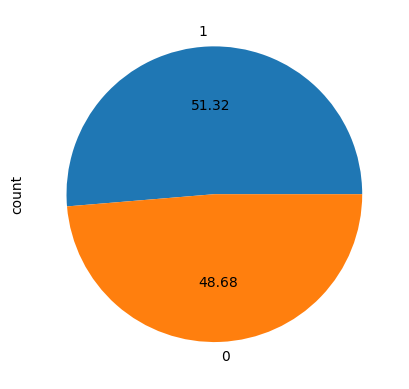

In [24]:
# Find percentage of each class/ratio of each class\n",
# Draw Pie plot to know the percentage of each class/ ratio of each class\n",
heart_disease_dataset['target'].value_counts().plot(kind = 'pie', autopct = '%0.2f')
plt.show()

In [25]:
# splitting different features / variables
X = heart_disease_dataset.drop(columns = 'target', axis = 1) # axis = 1 for drop column, axis =0 for drop row
Y = heart_disease_dataset['target']
# SHOW THE SEPARATED FEATURES AND TARGET
print(X)

      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0      52    1   0       125   212    0        1      168      0      1.0   
1      53    1   0       140   203    1        0      155      1      3.1   
2      70    1   0       145   174    0        1      125      1      2.6   
3      61    1   0       148   203    0        1      161      0      0.0   
4      62    0   0       138   294    1        1      106      0      1.9   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  
0         2   2     3  
1         0   0     3  
2  

In [26]:
# SPLITING THE DATASET INTO TRAINING DATA AND TEST DATA\n",
[X_train, X_test, Y_train, Y_test] = train_test_split(X,Y, test_size = 0.20, stratify = Y, random_state = 2)
print(X.shape, X_train.shape, X_test.shape)

(1025, 13) (820, 13) (205, 13)


In [27]:

# Initialize and train the model
linear_model = LogisticRegression(max_iter=1000)

linear_model.fit(X_train, Y_train)

print("Intercept (Bias):", linear_model.intercept_)
print("Coefficients (Weights):", linear_model.coef_)

# Generate predictions
Y_train_pred = linear_model.predict(X_train)
Y_test_pred = linear_model.predict(X_test)

# Generate probabilities for ROC-AUC
Y_test_prob = linear_model.predict_proba(X_test)[:, 1]


Intercept (Bias): [3.33939946]
Coefficients (Weights): [[-0.01294832 -1.68029078  0.78646481 -0.01531035 -0.00514636  0.05276542
   0.29167432  0.02633155 -1.11874828 -0.51786552  0.48736506 -0.76543385
  -0.99237051]]


In [28]:
linear_model.fit(X_train, Y_train)

LogisticRegression(max_iter=1000)

In [29]:
print("Intercept (Bias):\", linear_model.intercept_")  # Bias term\n",
print("Coefficients (Weights):\", linear_model.coef_")

Intercept (Bias):", linear_model.intercept_
Coefficients (Weights):", linear_model.coef_


In [30]:
X_train_data_prediction = linear_model.predict(X_train)

In [31]:
# Count value of each class (0 and 1) in training dataset\n",
Y_train.value_counts()

,count
target,
1,421
0,399


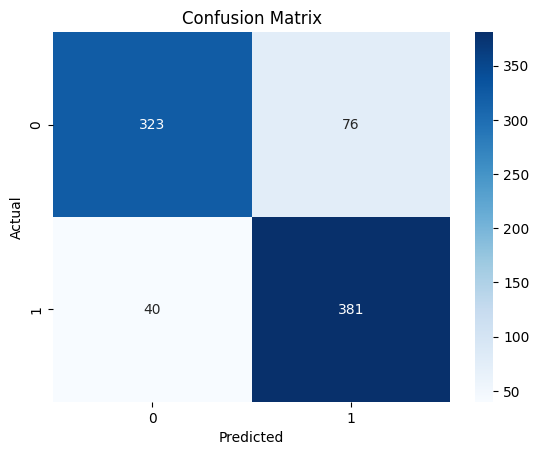

In [32]:
#Confusion Matrix. A confusion matrix shows true & false predictions in a tabular format.
cm = confusion_matrix(Y_train, X_train_data_prediction)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [33]:
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(Y_train, X_train_data_prediction)
print(cm)

[[323  76]
 [ 40 381]]


In [34]:
# Creating  a confusion matrix,which compares the y_test and y_pred\n",
[TN, FP, FN, TP] = confusion_matrix(Y_train, X_train_data_prediction).ravel()
[TN, FP, FN, TP]

[np.int64(323), np.int64(76), np.int64(40), np.int64(381)]

In [35]:

# Evaluate model on test data
print("Test Accuracy:", accuracy_score(Y_test, Y_test_pred))
print("Test Precision:", precision_score(Y_test, Y_test_pred))
print("Test Recall:", recall_score(Y_test, Y_test_pred))
print("Test F1-Score:", f1_score(Y_test, Y_test_pred))

roc_auc = auc(
    *roc_curve(Y_test, Y_test_prob)[:2]
)

print("Test ROC-AUC:", roc_auc)


Test Accuracy: 0.8146341463414634
Test Precision: 0.7863247863247863
Test Recall: 0.8761904761904762
Test F1-Score: 0.8288288288288288
Test ROC-AUC: 0.8985714285714286


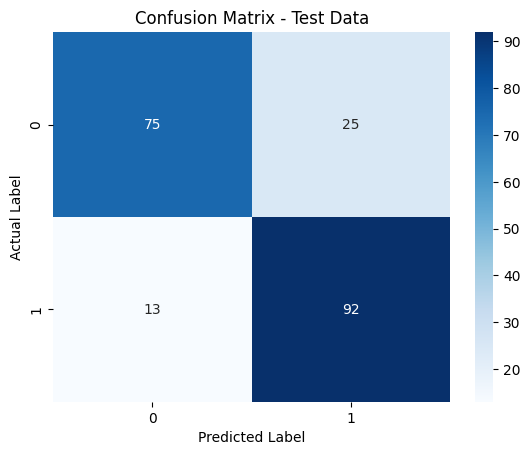

Confusion Matrix:
[[75 25]
 [13 92]]


In [36]:

cm = confusion_matrix(Y_test, Y_test_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Test Data")
plt.show()

print("Confusion Matrix:")
print(cm)


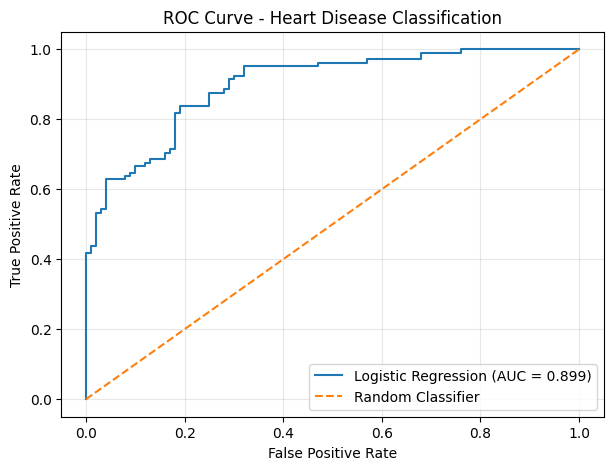

In [37]:

fpr, tpr, thresholds = roc_curve(Y_test, Y_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Heart Disease Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [38]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

train_pred = linear_model.predict(X_train)
test_pred = linear_model.predict(X_test)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Training": [
        accuracy_score(Y_train, train_pred),
        precision_score(Y_train, train_pred),
        recall_score(Y_train, train_pred),
        f1_score(Y_train, train_pred)
    ],
    "Testing": [
        accuracy_score(Y_test, test_pred),
        precision_score(Y_test, test_pred),
        recall_score(Y_test, test_pred),
        f1_score(Y_test, test_pred)
    ]
})

print(results.round(4).to_string(index=False))


   Metric  Training  Testing
 Accuracy    0.8585   0.8146
Precision    0.8337   0.7863
   Recall    0.9050   0.8762
 F1-Score    0.8679   0.8288


## Results and Observations

The Logistic Regression model was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

The model achieved a test accuracy of **81.46%**, a precision of **78.63%**, a recall of **87.62%**, and an F1-score of **82.88%**. The test ROC-AUC was **0.8986**, indicating good discrimination between the two target classes on the evaluated test split.

The confusion matrix showed 92 true positives, 75 true negatives, 25 false positives, and 13 false negatives. The training and testing metrics were reasonably close, with a test accuracy approximately 4.39 percentage points below training accuracy.

## Conclusion

This experiment demonstrates how Logistic Regression can be used for binary classification on a heart disease dataset. Exploratory data analysis helped examine the dataset, while the confusion matrix and evaluation metrics provided a broader assessment of model performance.

The results provide a useful baseline for further experiments with feature scaling, cross-validation, and alternative classification algorithms. This project is an educational machine learning exercise and is not intended for clinical diagnosis or medical decision-making.